Device: mps
HAM10000: 10015
label
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64
  ISIC2019 lesion_id grouping from ISIC_2019_Training_Metadata.csv: 12801/14885 images grouped by lesion
ISIC2019: 24703 -> 14885 after removing 9818 HAM10000 duplicates
label
nv       6170
mel      3409
bcc      2809
bkl      1525
akiec     737
df        124
vasc      111
Name: count, dtype: int64
Combined: 24900
Train 17786 | Val 3557 | Test 3557 (no shared lesions)
        train   val  test
source                   
isic    10632  2126  2127
ham      7154  1431  1430
Class weights: {'akiec': np.float32(3.3476), 'bcc': np.float32(1.0698), 'bkl': np.float32(1.3558), 'df': np.float32(14.8588), 'mel': np.float32(0.7866), 'nv': np.float32(0.2763), 'vasc': np.float32(14.0379)}
[Stage 1] Epoch 01/50 | train 1.8407 | val 1.0545 | val_acc 0.2168 | 295s *saved*
[Stage 1] Epoch 02/50 | train 1.3802 | val 1.1163 | val_acc 0.2789 | 298s *sa

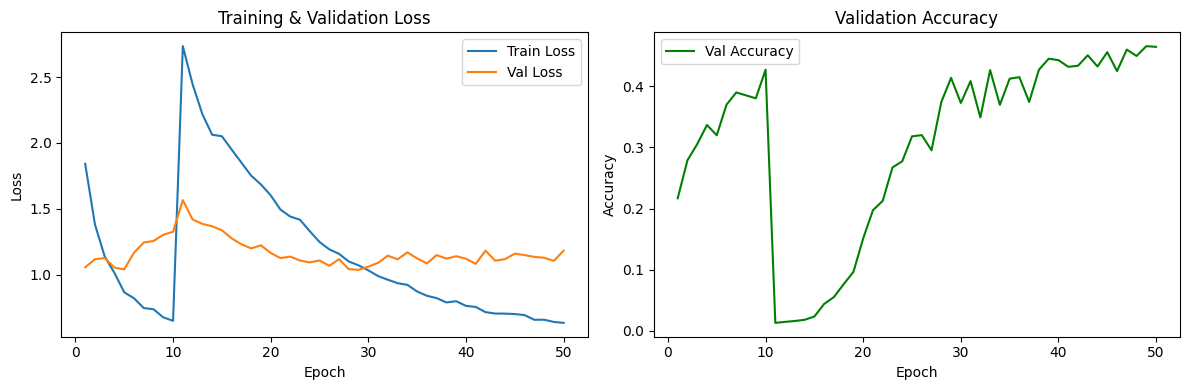

In [1]:
# ===================== CELL 1: TRAIN EfficientCapsNet ON HAM10000 + ISIC2019 (COMBINED) =====================
# Run from inside "CV Lab Project/".   pip install torch torchvision pandas numpy scikit-learn matplotlib seaborn pillow
# Training set = HAM10000 + ISIC2019 (HAM10000 duplicates removed from ISIC2019, SCC dropped).
# Leakage controls: lesion-grouped train/val/test split stratified by (dataset, class) so every split contains both datasets;
# class weights + oversampling + augmentation from the train split only; best epoch chosen on val only.
# The held-out test split is later evaluated separately on its HAM10000 part (cell 2) and its ISIC2019 part (cell 3).
import time, random
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms, models
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score, roc_curve, auc,
                             balanced_accuracy_score, average_precision_score)
from sklearn.preprocessing import label_binarize

# ---- paths
BASE_DIR  = Path.cwd()
DATA_DIR  = BASE_DIR / "data"
HAM_CSV   = DATA_DIR / "HAM10000_metadata.csv"
HAM_IMGS  = DATA_DIR / "images"
ISIC_DIR  = DATA_DIR / "ISIC2019_Dataset"
MODEL_DIR = BASE_DIR / "models"; OUT_DIR = BASE_DIR / "research_results"
MODEL_DIR.mkdir(exist_ok=True); OUT_DIR.mkdir(exist_ok=True)
CKPT_PATH = MODEL_DIR / "efficientcapsnet_combined_best.pth"

# ---- config (paper, Table 2)
CLASSES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]; C = len(CLASSES)
IMG_SIZE, BATCH_SIZE, EPOCHS = 224, 6, 50
STAGE1_END, STAGE2_END = 10, 30
LR_HEAD, LR_FT = 3e-4, 1e-5
ROUTING_ITERS, LAMBDA_ROUTE, FOCAL_GAMMA, LOGIT_SCALE = 3, 0.5, 2.0, 10.0
SEED, NUM_WORKERS = 42, 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("Device:", DEVICE)

# ---- data
CLS_IDX = {c: i for i, c in enumerate(CLASSES)}
ham = pd.read_csv(HAM_CSV)
_p = {p.stem: str(p) for p in HAM_IMGS.rglob("*.jpg")}
ham = ham[ham["image_id"].isin(_p)].copy()
ham["path"] = ham["image_id"].map(_p); ham["label"] = ham["dx"]
ham["group"] = "ham_" + ham["lesion_id"].astype(str); ham["y"] = ham["label"].map(CLS_IDX); ham["source"] = "ham"
ham = ham[["image_id", "path", "label", "group", "y", "source"]].reset_index(drop=True)
print("HAM10000:", len(ham)); print(ham["label"].value_counts())

ISIC_FOLDER_TO_DX = {"AK": "akiec", "BCC": "bcc", "BKL": "bkl", "DF": "df", "MEL": "mel", "NV": "nv", "VASC": "vasc"}  # SCC dropped
def build_isic_deduped():
    rows = [(p.stem, str(p), dx) for f, dx in ISIC_FOLDER_TO_DX.items() for p in (ISIC_DIR / f).rglob("*.jpg")]
    d = pd.DataFrame(rows, columns=["image_id", "path", "label"]); n0 = len(d)
    d = d[~d["image_id"].isin(set(ham["image_id"]))].reset_index(drop=True)   # remove HAM10000 duplicates
    d["y"] = d["label"].map(CLS_IDX); d["source"] = "isic"
    d["group"] = "isic_" + d["image_id"]                                      # fallback: one image = one group
    for m in ISIC_DIR.rglob("*Metadata*.csv"):                                # use lesion_id if ISIC2019 metadata is present
        meta = pd.read_csv(m)
        if {"image", "lesion_id"} <= set(meta.columns):
            lm = meta.dropna(subset=["lesion_id"]).set_index("image")["lesion_id"].astype(str)
            has = d["image_id"].map(lm)
            d["group"] = np.where(has.notna(), "isic_" + has.fillna(""), d["group"])
            print(f"  ISIC2019 lesion_id grouping from {m.name}: {has.notna().sum()}/{len(d)} images grouped by lesion"); break
    print(f"ISIC2019: {n0} -> {len(d)} after removing {n0 - len(d)} HAM10000 duplicates"); return d

isic_df = build_isic_deduped(); print(isic_df["label"].value_counts())
all_df = pd.concat([ham, isic_df[ham.columns]], ignore_index=True)
print("Combined:", len(all_df))

# lesion-grouped split, stratified by (dataset, class) so both datasets appear in train / val / test
all_df["strat"] = pd.factorize(all_df["source"] + "_" + all_df["label"])[0]
sg = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
trval_i, test_i = next(sg.split(all_df, all_df["strat"], all_df["group"]))
trval, test_df = all_df.iloc[trval_i].reset_index(drop=True), all_df.iloc[test_i].reset_index(drop=True)
sg2 = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=SEED)
tr_i, va_i = next(sg2.split(trval, trval["strat"], trval["group"]))
train_df, val_df = trval.iloc[tr_i].reset_index(drop=True), trval.iloc[va_i].reset_index(drop=True)
assert not (set(train_df.group) & set(val_df.group)) and not (set(train_df.group) & set(test_df.group)) \
   and not (set(val_df.group) & set(test_df.group)), "lesion leakage!"
assert not (set(train_df.image_id) & set(test_df.image_id)) and not (set(val_df.image_id) & set(test_df.image_id)), "image leakage!"
print(f"Train {len(train_df)} | Val {len(val_df)} | Test {len(test_df)} (no shared lesions)")
print(pd.DataFrame({"train": train_df["source"].value_counts(), "val": val_df["source"].value_counts(), "test": test_df["source"].value_counts()}))

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
gray = transforms.Grayscale(num_output_channels=3)
train_tf = transforms.Compose([gray, transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.RandomHorizontalFlip(),
    transforms.RandomAffine(degrees=30, translate=(0.2, 0.2), scale=(0.8, 1.2), shear=11),
    transforms.ColorJitter(brightness=(0.9, 1.1)), transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose([gray, transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class LesionDS(Dataset):
    def __init__(self, df, tf): self.df, self.tf = df.reset_index(drop=True), tf
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]; return self.tf(Image.open(r["path"]).convert("RGB")), int(r["y"])

# ---- model
def squash(s, dim=-1, eps=1e-8):
    n2 = (s ** 2).sum(dim, keepdim=True); return (n2 / (1 + n2)) * s / torch.sqrt(n2 + eps)   # Eq. (1)

class CapsuleHead(nn.Module):
    def __init__(self, in_ch, class_weights, prim_caps_ch=32, prim_dim=8, out_dim=16, grid=7, iters=ROUTING_ITERS, lam=LAMBDA_ROUTE):
        super().__init__()
        self.prim_dim, self.iters, self.lam = prim_dim, iters, lam
        self.proj = nn.Sequential(nn.Conv2d(in_ch, prim_caps_ch * prim_dim, 1), nn.ReLU())
        self.n_in = prim_caps_ch * grid * grid
        self.W = nn.Parameter(0.05 * torch.randn(self.n_in, C, out_dim, prim_dim))
        self.register_buffer("log_cw", torch.log(class_weights))
    def forward(self, f):
        B = f.size(0); p = self.proj(f)
        p = p.view(B, -1, self.prim_dim, p.size(2), p.size(3))
        u = squash(p.permute(0, 1, 3, 4, 2).reshape(B, -1, self.prim_dim))
        u_hat = torch.einsum("jcdk,bjk->bjcd", self.W, u)
        b = torch.zeros(B, self.n_in, C, device=f.device)
        for _ in range(self.iters):
            c = F.softmax(b + self.lam * self.log_cw, dim=2)                 # imbalance-aware routing logits
            v = squash((c.unsqueeze(-1) * u_hat).sum(1))
            b = b + (u_hat * v.unsqueeze(1)).sum(-1)
        return v.norm(dim=-1)

class EfficientCapsNet(nn.Module):
    def __init__(self, class_weights):
        super().__init__()
        self.features = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1).features
        self.head = CapsuleHead(1280, class_weights)
    def forward(self, x): return self.head(self.features(x))

class WeightedFocalLoss(nn.Module):
    def __init__(self, class_weights, gamma=FOCAL_GAMMA):
        super().__init__(); self.register_buffer("w", class_weights); self.gamma = gamma
    def forward(self, norms, y):
        logpt = F.log_softmax(norms * LOGIT_SCALE, 1).gather(1, y[:, None]).squeeze(1)
        return (-self.w[y] * (1 - logpt.exp()) ** self.gamma * logpt).mean()

def set_train_mode(model, stage):
    model.train(); model.features.eval()
    if stage >= 2:
        for blk in model.features[-2:]: blk.train()

@torch.no_grad()
def predict(model, df):
    model.eval(); ys, ps = [], []
    for x, y in DataLoader(LesionDS(df, eval_tf), BATCH_SIZE, num_workers=NUM_WORKERS):
        ps.append(F.softmax(model(x.to(DEVICE)) * LOGIT_SCALE, 1).cpu().numpy()); ys.append(y.numpy())
    return np.concatenate(ys), np.concatenate(ps)

def report(title, y, prob):
    pred = prob.argmax(1)
    print("\n" + "=" * 70 + f"\n{title} (n={len(y)})\n" + "=" * 70)
    print("Accuracy:", round(accuracy_score(y, pred), 4), "| Balanced acc:", round(balanced_accuracy_score(y, pred), 4))
    print(classification_report(y, pred, labels=range(C), target_names=CLASSES, digits=4, zero_division=0))
    safe = "".join(ch if ch.isalnum() else "_" for ch in title)
    plt.figure(figsize=(8, 6)); sns.heatmap(confusion_matrix(y, pred, labels=range(C)), annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES)
    plt.xlabel("Predicted Label"); plt.ylabel("True Label"); plt.title(f"Confusion Matrix - {title}"); plt.tight_layout()
    plt.savefig(OUT_DIR / f"ecn_{safe}_confusion.png", dpi=200); plt.show()
    yb = label_binarize(y, classes=range(C)); plt.figure(figsize=(8, 6))
    for i, c in enumerate(CLASSES):
        if yb[:, i].sum() == 0: continue
        fpr, tpr, _ = roc_curve(yb[:, i], prob[:, i]); plt.plot(fpr, tpr, label=f"{c} (AUC = {auc(fpr, tpr):.3f})")
        print(f"{c}: AP = {average_precision_score(yb[:, i], prob[:, i]):.4f}")
    plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
    plt.title(f"Multiclass ROC - {title}"); plt.legend(loc="lower right"); plt.tight_layout()
    plt.savefig(OUT_DIR / f"ecn_{safe}_roc.png", dpi=200); plt.show()

# ---- training (Algorithm 1, 3-stage transfer learning)
counts = train_df["y"].value_counts().reindex(range(C)).values.astype(float)
cw = torch.tensor(len(train_df) / (C * counts), dtype=torch.float32)          # Cw = N / (C * Nc), train only
print("Class weights:", dict(zip(CLASSES, cw.numpy().round(4))))
sampler = WeightedRandomSampler((1.0 / np.sqrt(counts))[train_df["y"].values], num_samples=len(train_df), replacement=True)
train_loader = DataLoader(LesionDS(train_df, train_tf), BATCH_SIZE, sampler=sampler, num_workers=NUM_WORKERS)
val_loader = DataLoader(LesionDS(val_df, eval_tf), BATCH_SIZE, num_workers=NUM_WORKERS)

model = EfficientCapsNet(cw.to(DEVICE)).to(DEVICE)
criterion = WeightedFocalLoss(cw.to(DEVICE)).to(DEVICE)
for p in model.features.parameters(): p.requires_grad = False
optimizer = torch.optim.AdamW(model.head.parameters(), lr=LR_HEAD)           # Stage 1
history = {"tr_loss": [], "val_loss": [], "val_acc": []}; best_acc, stage = 0.0, 1
for epoch in range(1, EPOCHS + 1):
    if epoch == STAGE1_END + 1:                                              # Stage 2: unfreeze last two blocks
        stage = 2
        for blk in model.features[-2:]:
            for p in blk.parameters(): p.requires_grad = True
        optimizer = torch.optim.AdamW(list(model.head.parameters()) + [p for blk in model.features[-2:] for p in blk.parameters()], lr=LR_FT)
    elif epoch == STAGE2_END + 1:
        stage = 3
    set_train_mode(model, stage); t0, run = time.time(), 0.0
    for x, y in train_loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad(); loss = criterion(model(x), y); loss.backward(); optimizer.step()
        run += loss.item() * x.size(0)
    tr_loss = run / len(train_df)
    model.eval(); vl, correct = 0.0, 0
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(DEVICE), y.to(DEVICE); o = model(x)
            vl += criterion(o, y).item() * x.size(0); correct += (o.argmax(1) == y).sum().item()
    val_loss, val_acc = vl / len(val_df), correct / len(val_df)
    history["tr_loss"].append(tr_loss); history["val_loss"].append(val_loss); history["val_acc"].append(val_acc)
    flag = ""
    if val_acc > best_acc: best_acc = val_acc; torch.save(model.state_dict(), CKPT_PATH); flag = " *saved*"
    print(f"[Stage {stage}] Epoch {epoch:02d}/{EPOCHS} | train {tr_loss:.4f} | val {val_loss:.4f} | val_acc {val_acc:.4f} | {time.time()-t0:.0f}s{flag}")

model.load_state_dict(torch.load(CKPT_PATH, map_location=DEVICE)); model.eval()
ep = range(1, len(history["tr_loss"]) + 1); fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ep, history["tr_loss"], label="Train Loss"); ax[0].plot(ep, history["val_loss"], label="Val Loss")
ax[0].set_title("Training & Validation Loss"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Loss"); ax[0].legend()
ax[1].plot(ep, history["val_acc"], color="green", label="Val Accuracy"); ax[1].set_title("Validation Accuracy")
ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy"); ax[1].legend(); plt.tight_layout()
plt.savefig(OUT_DIR / "ecn_accuracy_loss_curves.png", dpi=200); plt.show()



Combined test (HAM10000 + ISIC2019) (n=3557)
Accuracy: 0.4523 | Balanced acc: 0.4304
              precision    recall  f1-score   support

       akiec     0.1931    0.5526    0.2862       152
         bcc     0.5438    0.3797    0.4472       474
         bkl     0.2404    0.3840    0.2957       375
          df     0.0741    0.2353    0.1127        34
         mel     0.3694    0.5387    0.4383       646
          nv     0.8961    0.4500    0.5991      1840
        vasc     0.0780    0.4722    0.1339        36

    accuracy                         0.4523      3557
   macro avg     0.3421    0.4304    0.3304      3557
weighted avg     0.6382    0.4523    0.4950      3557



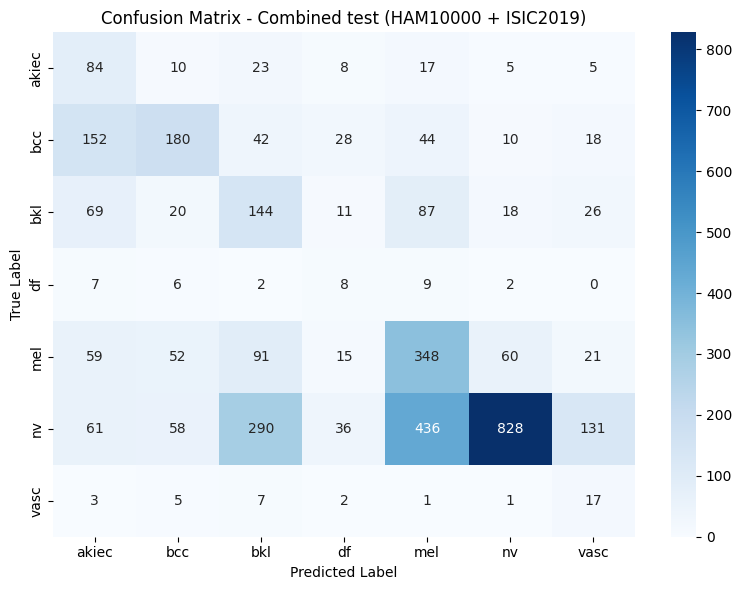

akiec: AP = 0.1849
bcc: AP = 0.5278
bkl: AP = 0.2474
df: AP = 0.1064
mel: AP = 0.3586
nv: AP = 0.8562
vasc: AP = 0.1515


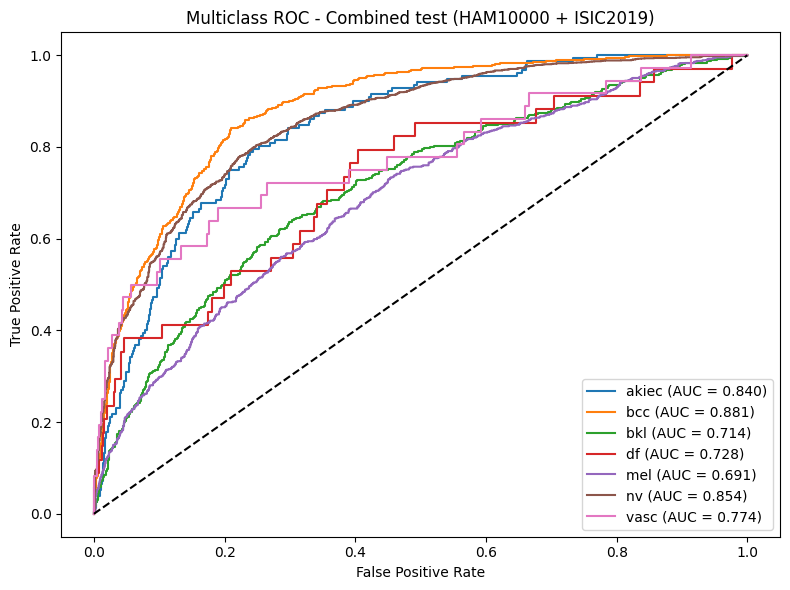


SUMMARY
                                       n  accuracy  balanced_acc  macro_F1  weighted_F1  macro_AUC_ovr
split                                                                                                 
Combined test                       3557    0.4523        0.4304    0.3304       0.4950         0.7832
Combined val (checkpoint-selected)  3557    0.4653        0.4695    0.3518       0.5043         0.8029
HAM10000 part of test               1430    0.5406        0.4783    0.3602       0.5966         0.7999
ISIC2019 part of test               2127    0.3930        0.3661    0.2895       0.4185         0.7607

               precision  recall  f1-score    support
akiec            0.1931  0.5526    0.2862   152.0000
bcc              0.5438  0.3797    0.4472   474.0000
bkl              0.2404  0.3840    0.2957   375.0000
df               0.0741  0.2353    0.1127    34.0000
mel              0.3694  0.5387    0.4383   646.0000
nv               0.8961  0.4500    0.5991  1840.0000


In [4]:
# ===================== CELL 1b: EVALUATE ON THE FULL COMBINED SPLITS (HAM10000 + ISIC2019 together) =====================
# Run in the same kernel after cell 1 (needs: model, test_df, val_df, predict, report, CLASSES, C, OUT_DIR).
# `model` already holds the best-val checkpoint (loaded at the end of cell 1).
from sklearn.metrics import f1_score, roc_auc_score

def summary(y, prob, name):
    pred = prob.argmax(1)
    try: auc_macro = roc_auc_score(y, prob, multi_class="ovr", average="macro", labels=list(range(C)))
    except ValueError: auc_macro = float("nan")
    return {"split": name, "n": len(y),
            "accuracy": accuracy_score(y, pred), "balanced_acc": balanced_accuracy_score(y, pred),
            "macro_F1": f1_score(y, pred, average="macro", labels=list(range(C)), zero_division=0),
            "weighted_F1": f1_score(y, pred, average="weighted", labels=list(range(C)), zero_division=0),
            "macro_AUC_ovr": auc_macro}

# 1) Full combined TEST split (the number to report) -> full per-class report, confusion matrix, ROC/AP
y_te, p_te = predict(model, test_df)
report("Combined test (HAM10000 + ISIC2019)", y_te, p_te)

# 2) Combined VAL split (for reference only; the checkpoint was selected on it, so it is optimistic)
y_va, p_va = predict(model, val_df)

# 3) Side-by-side summary: combined vs each dataset's part of the test split
rows = [summary(y_te, p_te, "Combined test"), summary(y_va, p_va, "Combined val (checkpoint-selected)")]
for src_name, label in [("ham", "HAM10000 part of test"), ("isic", "ISIC2019 part of test")]:
    m = (test_df["source"] == src_name).values
    rows.append(summary(y_te[m], p_te[m], label))
summ = pd.DataFrame(rows).set_index("split").round(4)
print("\n" + "=" * 70 + "\nSUMMARY\n" + "=" * 70); print(summ.to_string())
summ.to_csv(OUT_DIR / "ecn_combined_summary_metrics.csv")

# 4) Per-class recall / precision / F1 on the combined test split as a table (saved too)
cr = pd.DataFrame(classification_report(y_te, p_te.argmax(1), labels=range(C), target_names=CLASSES,
                                        output_dict=True, zero_division=0)).T.round(4)
cr.to_csv(OUT_DIR / "ecn_combined_test_per_class.csv"); print("\n", cr.to_string())


label
nv       958
mel      159
bkl      157
bcc       73
akiec     47
vasc      20
df        16
Name: count, dtype: int64

HAM10000 test (combined-trained) (n=1430)
Accuracy: 0.5406 | Balanced acc: 0.4783
              precision    recall  f1-score   support

       akiec     0.1818    0.3404    0.2370        47
         bcc     0.4304    0.4658    0.4474        73
         bkl     0.2918    0.4777    0.3623       157
          df     0.1538    0.3750    0.2182        16
         mel     0.2714    0.4591    0.3411       159
          nv     0.9521    0.5804    0.7211       958
        vasc     0.1140    0.6500    0.1940        20

    accuracy                         0.5406      1430
   macro avg     0.3422    0.4783    0.3602      1430
weighted avg     0.7313    0.5406    0.5966      1430



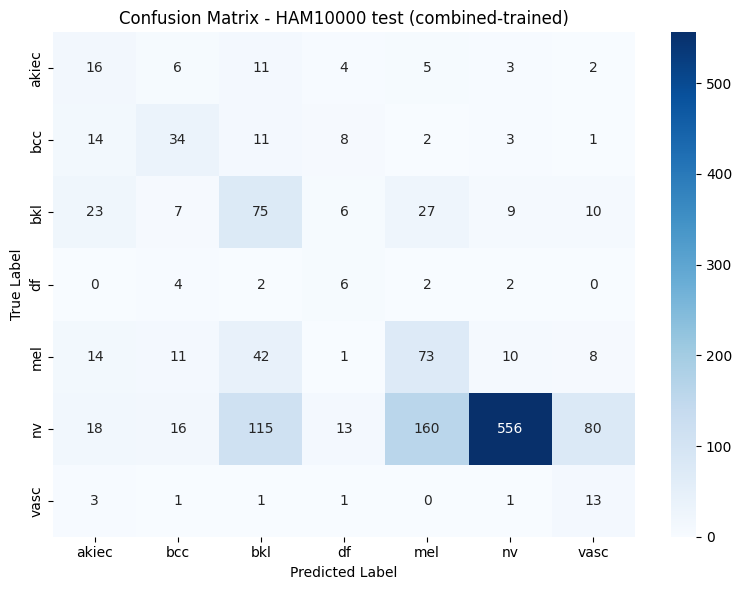

akiec: AP = 0.1623
bcc: AP = 0.4541
bkl: AP = 0.3422
df: AP = 0.2333
mel: AP = 0.2220
nv: AP = 0.9323
vasc: AP = 0.2811


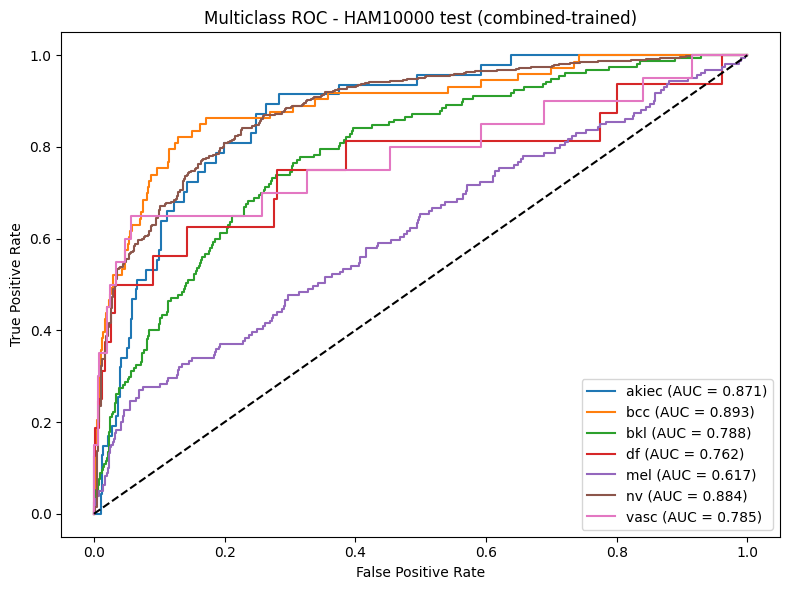

In [2]:
# ===================== CELL 2: TEST ON HAM10000 (held-out part of the combined test split) =====================
ham_test = test_df[test_df["source"] == "ham"].reset_index(drop=True)
print(ham_test["label"].value_counts())
y_ham, p_ham = predict(model, ham_test)
report("HAM10000 test (combined-trained)", y_ham, p_ham)


label
nv       882
mel      487
bcc      401
bkl      218
akiec    105
df        18
vasc      16
Name: count, dtype: int64

ISIC2019 test (combined-trained) (n=2127)
Accuracy: 0.393 | Balanced acc: 0.3661
              precision    recall  f1-score   support

       akiec     0.1960    0.6476    0.3009       105
         bcc     0.5794    0.3641    0.4472       401
         bkl     0.2018    0.3165    0.2464       218
          df     0.0290    0.1111    0.0460        18
         mel     0.4086    0.5647    0.4741       487
          nv     0.8000    0.3084    0.4452       882
        vasc     0.0385    0.2500    0.0667        16

    accuracy                         0.3930      2127
   macro avg     0.3219    0.3661    0.2895      2127
weighted avg     0.5654    0.3930    0.4185      2127



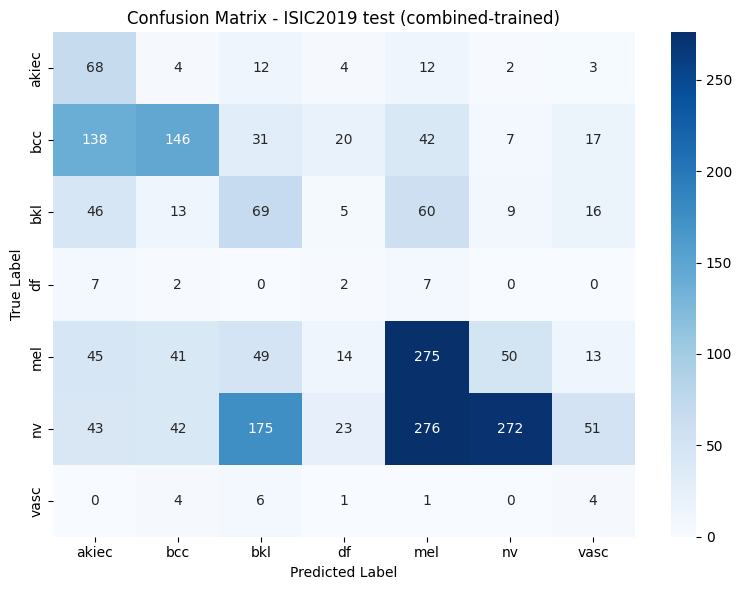

akiec: AP = 0.2137
bcc: AP = 0.5503
bkl: AP = 0.1891
df: AP = 0.0218
mel: AP = 0.4262
nv: AP = 0.7402
vasc: AP = 0.0358


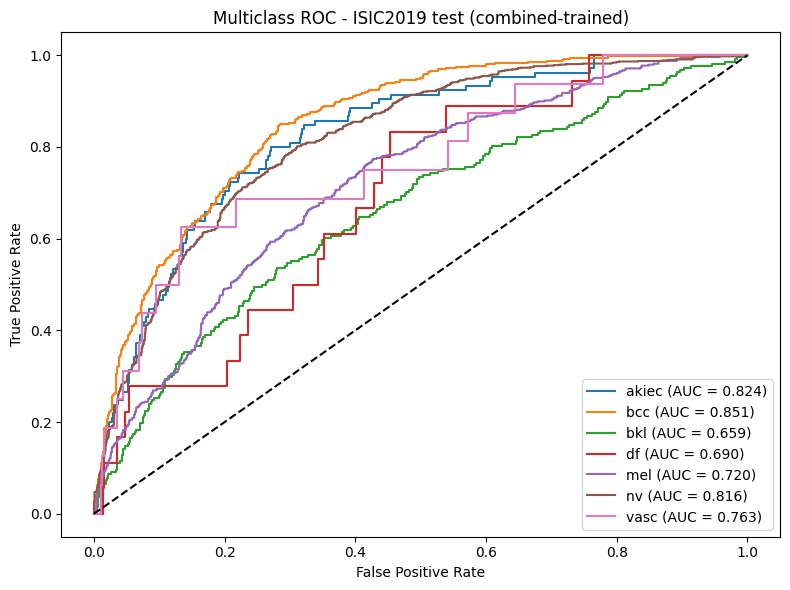

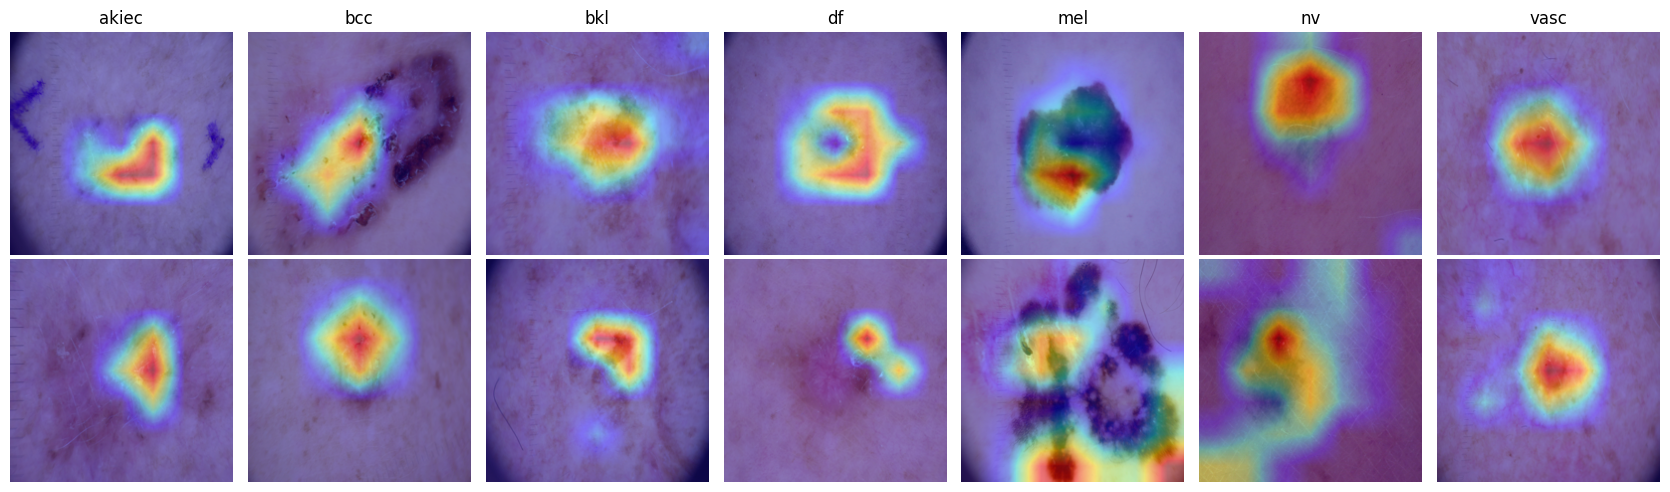

In [3]:
# ===================== CELL 3: TEST ON ISIC2019 (held-out part of the combined test split) =====================
isic_test = test_df[test_df["source"] == "isic"].reset_index(drop=True)
print(isic_test["label"].value_counts())
y_isic, p_isic = predict(model, isic_test)
report("ISIC2019 test (combined-trained)", y_isic, p_isic)

# Grad-CAM samples (last EfficientNet block) from the held-out test split (both datasets)
comb_df = test_df
acts, grads = {}, {}; layer = model.features[-1]
h1 = layer.register_forward_hook(lambda m, i, o: acts.update(a=o))
h2 = layer.register_full_backward_hook(lambda m, gi, go: grads.update(g=go[0]))
fig, axs = plt.subplots(2, C, figsize=(2.4 * C, 5))
for j, cls in enumerate(CLASSES):
    for i, (_, r) in enumerate(comb_df[comb_df["label"] == cls].head(2).iterrows()):
        img = Image.open(r["path"]).convert("RGB"); x = eval_tf(img).unsqueeze(0).to(DEVICE).requires_grad_(True)
        out = model(x); model.zero_grad(); out[0, out.argmax()].backward()
        w = grads["g"].mean((2, 3), keepdim=True); cam = F.relu((w * acts["a"]).sum(1, keepdim=True))
        cam = F.interpolate(cam, (IMG_SIZE, IMG_SIZE), mode="bilinear")[0, 0].detach().cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        axs[i, j].imshow(img.resize((IMG_SIZE, IMG_SIZE))); axs[i, j].imshow(cam, cmap="jet", alpha=0.45); axs[i, j].axis("off"); axs[0, j].set_title(cls)
h1.remove(); h2.remove(); plt.tight_layout(); plt.savefig(OUT_DIR / "ecn_gradcam_sample.png", dpi=200); plt.show()
